In [1]:
import os
import utils
import pickle
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import torchvision.transforms as T

from utils import *
from torchvision import datasets

device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

weights_path = "models_weights"

# CREATE DATASET

In [3]:
train_ds = datasets.FashionMNIST(root='data', train=True, download=True)
test_ds = datasets.FashionMNIST(root='data', train=False, download=True)
class_size = 10
(x_train, y_train), (x_test, y_test) = (train_ds.data.numpy(), train_ds.targets.numpy()), (test_ds.data.numpy(), test_ds.targets.numpy())
digit0 = 0
digit1 = 1
I_train0 = np.where(y_train==digit0)
I_train1 = np.where(y_train==digit1)
I_train = np.concatenate((I_train0[0][0:class_size],I_train1[0][0:class_size]))

y_train = [0]*class_size+[1]*class_size
y_train = np.array(y_train)
x_train = x_train[I_train]
I_test0 = np.where(y_test==digit0)
I_test1 = np.where(y_test==digit1)
I_test = np.concatenate((I_test0[0],I_test1[0]))
y_test = y_test[I_test]
for i in range(y_test.size):
    if y_test[i]==digit0:
        y_test[i]=0
    else:
        y_test[i]=1
x_test = x_test[I_test]

x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255      # 28x28
x_test /= 255
x_train = x_train.reshape((class_size*2,1,28,28))  # channels-first
x_test = x_test.reshape((x_test.shape[0],1,28,28))

print("TRAIN SHAPE", x_train.shape)
print("TEST SHAPE", x_test.shape)

TRAIN SHAPE (20, 1, 28, 28)
TEST SHAPE (2000, 1, 28, 28)


In [3]:
# stessi parametri dei layer Keras; RandomRotation(0.1) di Keras = ±0.1 * 360° = ±36°
data_augmentation = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomRotation(36),
    T.RandomAffine(degrees=0, scale=(1 - 0.005, 1 + 0.005)),        # RandomZoom
    T.RandomAffine(degrees=0, translate=(0.005, 0.005)),            # RandomTranslation
])

def augmented_dataset(images, labels, size):
    # ogni immagine occupa un blocco di size+1 posizioni: l'originale seguito da size versioni aumentate
    augmented_images = np.zeros([images.shape[0]*(size+1)]+list(images.shape[1:]), dtype=np.float32)
    augmented_labels = np.zeros((labels.shape[0]*(size+1)), dtype=labels.dtype)
    
    for i in range(images.shape[0]):
        start = i*(size+1)
        augmented_images[start] = images[i]
        augmented_labels[start] = labels[i]
        image = torch.as_tensor(images[i])
        for j in range(1,size+1):
            augmented_images[start+j] = data_augmentation(image).numpy()
            augmented_labels[start+j] = labels[i]
    return augmented_images, augmented_labels
    

TRAIN SHAPE (120, 1, 28, 28)


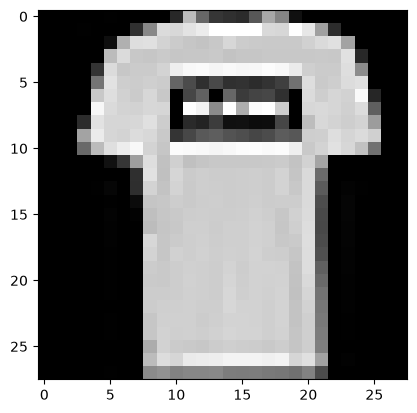

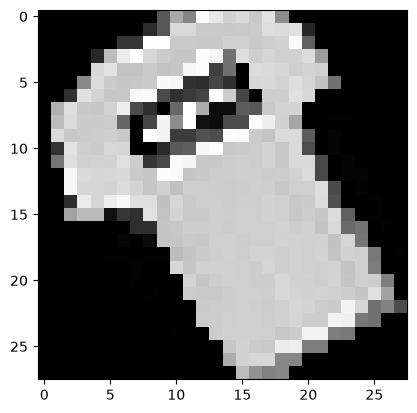

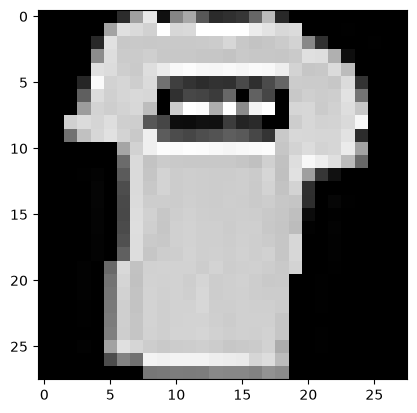

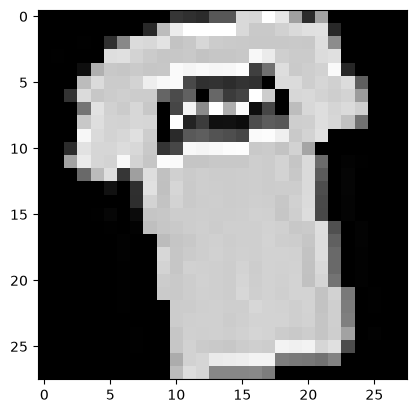

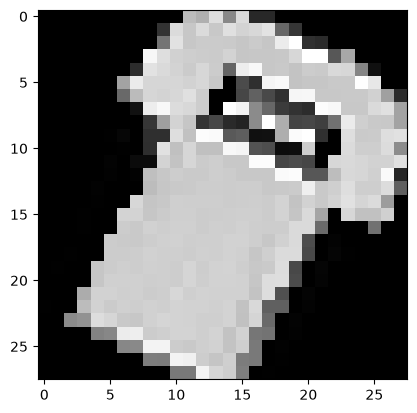

In [4]:
x_train_aug , y_train_aug = augmented_dataset(x_train,y_train, 5)
print("TRAIN SHAPE", x_train_aug.shape)

for i in range(5):
    plt.imshow(x_train_aug[i, 0], cmap = "gray")
    plt.show()

# CREATE MODEL

### MODEL WITHOUT AUGMENTATION

In [5]:
torch.manual_seed(0)  # stessa inizializzazione per entrambi i modelli: il confronto dipende solo dai dati
model_conv = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(64, 64, kernel_size=3), nn.ReLU(),
    nn.Flatten(),
    nn.Dropout(0.5),
    nn.LazyLinear(64), nn.ReLU(),  # in_features (64 * 3 * 3 = 576) calcolato al primo forward
    nn.Linear(64, 2)  # logits: la softmax è inclusa in CrossEntropyLoss
).to(device)

loss_fn = nn.CrossEntropyLoss()  # equivalente a softmax + sparse_categorical_crossentropy
summary(model_conv, (1, 28, 28))  # il forward fittizio inizializza anche LazyLinear
optimizer_conv = torch.optim.Adam(model_conv.parameters(), lr=1e-3)  # va creato dopo il forward

Layer (type)                Output Shape               Param #
0 (Conv2d)                  (None, 32, 26, 26)             320
1 (ReLU)                    (None, 32, 26, 26)               0
2 (MaxPool2d)               (None, 32, 13, 13)               0
3 (Conv2d)                  (None, 64, 11, 11)          18,496
4 (ReLU)                    (None, 64, 11, 11)               0
5 (MaxPool2d)               (None, 64, 5, 5)                 0
6 (Conv2d)                  (None, 64, 3, 3)            36,928
7 (ReLU)                    (None, 64, 3, 3)                 0
8 (Flatten)                 (None, 576)                      0
9 (Dropout)                 (None, 576)                      0
10 (Linear)                 (None, 64)                  36,928
11 (ReLU)                   (None, 64)                       0
12 (Linear)                 (None, 2)                      130
Total params: 92,802
Trainable params: 92,802
Non-trainable params: 0


### MODEL WITH AUGMENTATION

In [6]:
torch.manual_seed(0)  # stessa inizializzazione per entrambi i modelli: il confronto dipende solo dai dati
model_conva = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(64, 64, kernel_size=3), nn.ReLU(),
    nn.Flatten(),
    nn.Dropout(0.5),
    nn.LazyLinear(64), nn.ReLU(),  # in_features (64 * 3 * 3 = 576) calcolato al primo forward
    nn.Linear(64, 2)  # logits: la softmax è inclusa in CrossEntropyLoss
).to(device)

summary(model_conva, (1, 28, 28))  # il forward fittizio inizializza anche LazyLinear
optimizer_conva = torch.optim.Adam(model_conva.parameters(), lr=1e-3)  # va creato dopo il forward

Layer (type)                Output Shape               Param #
0 (Conv2d)                  (None, 32, 26, 26)             320
1 (ReLU)                    (None, 32, 26, 26)               0
2 (MaxPool2d)               (None, 32, 13, 13)               0
3 (Conv2d)                  (None, 64, 11, 11)          18,496
4 (ReLU)                    (None, 64, 11, 11)               0
5 (MaxPool2d)               (None, 64, 5, 5)                 0
6 (Conv2d)                  (None, 64, 3, 3)            36,928
7 (ReLU)                    (None, 64, 3, 3)                 0
8 (Flatten)                 (None, 576)                      0
9 (Dropout)                 (None, 576)                      0
10 (Linear)                 (None, 64)                  36,928
11 (ReLU)                   (None, 64)                       0
12 (Linear)                 (None, 2)                      130
Total params: 92,802
Trainable params: 92,802
Non-trainable params: 0


# TRAINING

### PARAMS

In [7]:
EPOCHS = 10
VERBOSE = 1
BS = 20

TRAIN = True

### MODEL WITHOUT AUGMENTATION

 20%|██        | 2/10 [00:00<00:01,  4.68it/s]

Epoch 1/10 - loss: 0.6946 - accuracy: 0.5000 - val_loss: 0.6905 - val_accuracy: 0.5000
Epoch 2/10 - loss: 0.6900 - accuracy: 0.5000 - val_loss: 0.6836 - val_accuracy: 0.5000


 40%|████      | 4/10 [00:00<00:00,  6.20it/s]

Epoch 3/10 - loss: 0.6840 - accuracy: 0.5000 - val_loss: 0.6740 - val_accuracy: 0.5000
Epoch 4/10 - loss: 0.6691 - accuracy: 0.5000 - val_loss: 0.6615 - val_accuracy: 0.5000


 60%|██████    | 6/10 [00:01<00:00,  6.40it/s]

Epoch 5/10 - loss: 0.6666 - accuracy: 0.5000 - val_loss: 0.6473 - val_accuracy: 0.5000
Epoch 6/10 - loss: 0.6523 - accuracy: 0.5000 - val_loss: 0.6291 - val_accuracy: 0.5090


 80%|████████  | 8/10 [00:01<00:00,  7.03it/s]

Epoch 7/10 - loss: 0.6241 - accuracy: 0.5500 - val_loss: 0.6043 - val_accuracy: 0.7415
Epoch 8/10 - loss: 0.6056 - accuracy: 0.7000 - val_loss: 0.5728 - val_accuracy: 0.9035


100%|██████████| 10/10 [00:01<00:00,  6.37it/s]

Epoch 9/10 - loss: 0.5753 - accuracy: 0.8000 - val_loss: 0.5344 - val_accuracy: 0.9400
Epoch 10/10 - loss: 0.5265 - accuracy: 0.9000 - val_loss: 0.4872 - val_accuracy: 0.9410


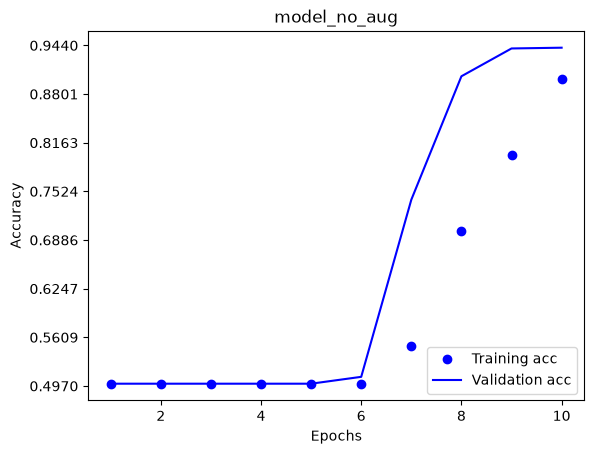

In [8]:
name = "model_no_aug"

exists = os.path.isfile(f'{weights_path}/{name}.hist') and os.path.isfile(f'{weights_path}/{name}.pt')
if exists and not TRAIN:
    with open(f'{weights_path}/{name}.hist','rb') as hist_file:
        history_dict = pickle.load(hist_file)
    model_conv.load_state_dict(torch.load(f'{weights_path}/{name}.pt', map_location=device))
else:
    history_dict = fit(model_conv, optimizer_conv, loss_fn, x_train, y_train, epochs=EPOCHS, verbose=VERBOSE, validation_data = (x_test, y_test), batch_size=BS)
    with open(f'{weights_path}/{name}.hist','wb') as hist_file:
        pickle.dump(history_dict, hist_file)
    torch.save(model_conv.state_dict(), f'{weights_path}/{name}.pt')
    
utils.hist_plot(history_dict, name)

score_conv = evaluate(model_conv, torch.as_tensor(x_test, dtype=torch.float32), torch.as_tensor(y_test, dtype=torch.long), loss_fn)
non_aug = score_conv[1]

 10%|█         | 1/10 [00:00<00:01,  5.90it/s]

Epoch 1/10 - loss: 0.6893 - accuracy: 0.5333 - val_loss: 0.6692 - val_accuracy: 0.9295


 20%|██        | 2/10 [00:00<00:01,  6.18it/s]

Epoch 2/10 - loss: 0.6439 - accuracy: 0.5250 - val_loss: 0.5726 - val_accuracy: 0.7710


 30%|███       | 3/10 [00:00<00:01,  6.33it/s]

Epoch 3/10 - loss: 0.4856 - accuracy: 0.8833 - val_loss: 0.3400 - val_accuracy: 0.9375


... (10 outputs left out)

 90%|█████████ | 9/10 [00:01<00:00,  5.85it/s]

Epoch 9/10 - loss: 0.0036 - accuracy: 1.0000 - val_loss: 0.1416 - val_accuracy: 0.9615


100%|██████████| 10/10 [00:01<00:00,  5.96it/s]

Epoch 10/10 - loss: 0.0047 - accuracy: 1.0000 - val_loss: 0.1591 - val_accuracy: 0.9585


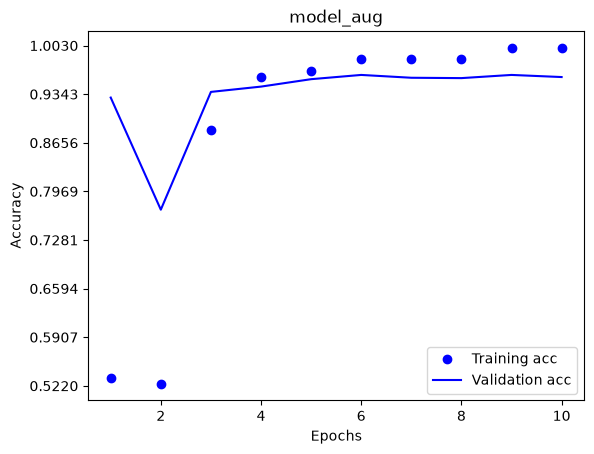

In [9]:
# MODIFICATORE RANDOM DEI DATI
name = "model_aug"

exists = os.path.isfile(f'{weights_path}/{name}.hist') and os.path.isfile(f'{weights_path}/{name}.pt')
if exists and not TRAIN:
    with open(f'{weights_path}/{name}.hist','rb') as hist_file:
        history_dict = pickle.load(hist_file)
    model_conva.load_state_dict(torch.load(f'{weights_path}/{name}.pt', map_location=device))
else:
    history_dict = fit(model_conva, optimizer_conva, loss_fn, x_train_aug, y_train_aug, epochs=EPOCHS, verbose=VERBOSE, validation_data = (x_test, y_test), batch_size=BS)
    with open(f'{weights_path}/{name}.hist','wb') as hist_file:
        pickle.dump(history_dict, hist_file)
    torch.save(model_conva.state_dict(), f'{weights_path}/{name}.pt')
    
utils.hist_plot(history_dict, name)

score_conv = evaluate(model_conva, torch.as_tensor(x_test, dtype=torch.float32), torch.as_tensor(y_test, dtype=torch.long), loss_fn)
augs = score_conv[1]

In [10]:
print(f'Modello Standard:  {non_aug:.4f}')
print(f'Data Augmentation: {augs:.4f}')

Modello Standard:  0.9410
Data Augmentation: 0.9585
